# 1D Lagrangian turbulence, B + Scat4: $D_k = D_{KL}(p\|q_k)$ per group of potentials

$p \propto \exp(-\sum_j \theta_j^T\phi_j)$, $A_k = \theta_k^T\phi_k$, $q_k \propto p\,e^{A_k}$;
$D_k = \log E_p[e^{A_k - E_p A_k}] \ge 0$ (nats). Code sign: $\log p = +\Theta\cdot\phi$, so $A_k = -C_k$.
Groups: summed energy of the group (never a sum of single $D_k$). $L_6$ is never removed.

**Assumptions** (flagged): $E_p$ is estimated on the GENERATED signals (law $\rho_1$ of the SDE endpoint) while
$\theta = \Theta_{reg}(t=1)$; $\hat D_k$ is exact only if $\rho_1 = p_{\Theta_{reg}}$. Error bar = max(std over seeds, bootstrap std).

**What the numbers mean:** $\hat D_k \le D_k$ (Jensen: $E\log\bar W \le \log E\bar W$, on average) and $I_k \le D_k$, with
$I_k = D_{KL}(p\|q_k^*)$ the information of term $k$ (other $\theta$ refitted). $\hat D_k$ and $I_k$ are not ordered.
Groups with degenerate weights (ESS < 100, or $\hat D_k$ still rising with N, or Pareto $\hat k \ge 0.5$ of the weights, in any seed) are shown as
LOWER BOUNDS $D_k \ge \hat D_k$ (open circles / "$\ge$"), no error bar: "removing this term alone, without
refit, changes p strongly", NOT "this term carries much information". Gaussian rule: $N \gg e^{\mathrm{Var}(A)/2} = e^{D_{KL}(q_k\|p)}$
samples needed (column log10_N_needed). $\frac12\mathrm{Var}(A_k)$ is the 2nd-cumulant approximation only.
Heavy computation: `kl_groups/launch_kl_groups.sh` (cache_energies.py + compute_H.py); this notebook only reads
`results/<TAG>/H_lagrangian.csv`.

## What this analysis can and cannot say (limits of $D_k$)

1. **$D_k$ is an upper bound of the information, not the information.** $D_k = D_{KL}(p\|q_k) \ge I_k = D_{KL}(p\|q_k^*)$:
   $q_k$ is $p$ with term $k$ removed and **no refit** of the other $\theta$; $q_k^*$ refits them. A large $D_k$ says
   "removing the term without compensation changes $p$ a lot", not "the term carries much information".
2. **The estimate is a lower bound of an upper bound.** $\hat D_k$ only sees the region of signal space reached by the $N$ samples
   (probability mass $\gtrsim 1/N$), so on average $\hat D_k \le D_k$. Hence a large $\hat D_k$ says **nothing** about $I_k$;
   only a small, *measured* $D_k$ gives an upper bound on $I_k$.
3. **When is it measured?** Needs $N \gtrsim e^{D_{KL}(q_k\|p)}$ (shape-free rule; $=e^{\frac12\mathrm{Var}(A_k)}$ only if $A_k$ is Gaussian). Scalar and Morlet banks: $\hat D_k \gg \ln N \approx 9.2$ ($N = 10^4$) and ESS $\approx 1$, so a few signals carry all the weight: **not measured**. How far from measured is unknown: the Gaussian value of $N$ (huge, from $\frac12$Var of thousands of nats) says nothing about the tail, which could need far fewer or far more samples. Scat4: $\hat D_k > \frac12$Var, so $A_k$ has a heavier tail than a Gaussian and the Gaussian $N$ is too small.
4. **Exponential sensitivity to $\Theta_{reg}$.** $D_k = \log E_p[e^{A_k - E A_k}]$: an error $\delta A$ enters through $e^{\delta A}$.
   $\Theta_{reg}$ here is the B+Scat4 one (L_6<0 solve NOTCONVERGED, $\lambda$ not chosen by the cross-seed rule), so the numbers
   are **conditional on this $\Theta_{reg}$**. In the Gaussian benchmark (d=16) a 2 % change of $\theta$ turned a $z\approx 1$ term from finite to infinite in ~50 % of cases.
5. **Second dependence: the samples.** $E_p$ is replaced by the SDE endpoint law $\rho_1$; any integration bias (the bound is not converged in nt)
   moves $\hat D_k$.
6. **Sampling-size benchmark (Gaussian d=16, exact $D$ known):** $\hat D_k / D$ has median 0.51 and was as low as 1/70 (low-pass term). The old
   ESS rule accepted such groups as "measured"; the $\hat k < 0.5$ criterion rejects them. $\hat k < 0.5$ is necessary, not shown sufficient.
7. $L_6$ is never a $D_k$ group ($q_k$ not normalisable); only its $\frac12$Var is reported.

**Result of `run1_v2` (this notebook): no family is measured** (all are lower bounds). Scat4 is the only family whose status could change with a better
$\Theta_{reg}$ (cancellation ratio of the single-term $\frac12$Var: 505 Real, 34 Imag), to be rechecked after the $\lambda$ rule.

In [1]:
import os, sys
from pathlib import Path
TAG = 'run1_v2'        # results/<TAG>
os.environ['KL_RESULTS'] = str(Path('results') / TAG)
sys.path.insert(0, '.')
import plots as P
import matplotlib.pyplot as plt
%matplotlib inline
DS = 'lagrangian'
df, agg = P.load(DS, Path(os.environ['KL_RESULTS']))
print(df.seed.unique(), 'seeds |', df.N.iloc[0], 'samples per seed')

[900 901 902 903 904] seeds | 10000 samples per seed


## $D_k$ per group, one marker per seed, with $\frac12$Var alongside

### $D_k$ per group, one marker per seed (nats, log scale)
- **o** D̂_k = log (1/N) Σ_i e^{a_i − ā}, a_i = A_k on the generated signals. Open circle = lower bound (D_k ≥ D̂_k):
  in that seed a few signals carry almost all the weight e^{a_i}, so the estimate misses the tail. Filled = measured.
- **x** ½Var(A_k): leading (2nd-cumulant) term of D_k; exact if A_k is Gaussian.
- **◆** mean ± std over seeds of D̂_k (for open circles: spread of the bounds, not an error bar on D_k).
- **Lower bound** now also when Pareto $\hat k \ge 0.5$ (heavy-tailed weights); the summary table at the end has `khat_max`.

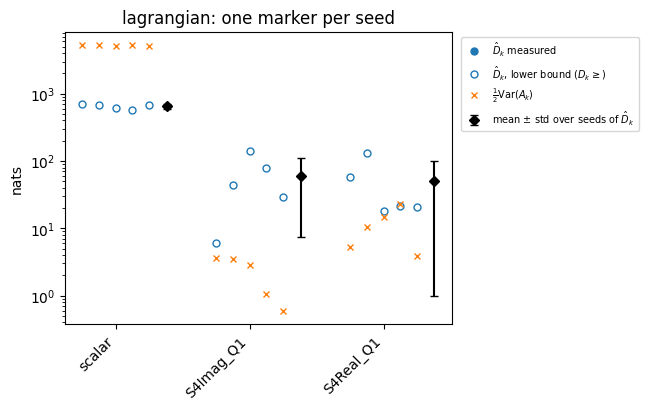

In [2]:
P.bars(agg, title=DS); plt.show()

Numbers behind the figure (same rows, same order; worst seed for ESS, wmax, khat). ESS = effective number of signals sharing the weight $e^{A_k - \bar A}$, out of $N$; wmax = share of the single heaviest signal. Measured needs ESS $\ge 100$ and $\hat k < 0.5$ (and no drift with N).

In [3]:
P.bars_table(agg).round(3)

,n_terms,D_hat (mean),1/2 Var,ESS_min,N,wmax,regime,khat_max
group,,,,,,,,
scalar,192,647.347,5233.610,1.0,10000,1.0,lower bound,45.547
S4Imag_Q1,56,59.907,2.323,1.0,10000,1.0,lower bound,2.535
S4Real_Q1,84,50.349,11.491,1.0,10000,1.0,lower bound,4.329


## $D_k$ per single potential, in the order of the potential list (Scat4: grouped by $j$, then $j'$, then $l$)
Same markers as the first figure (open triangle = lower bound, $\times$ = $\frac12$Var). One panel per potential category.

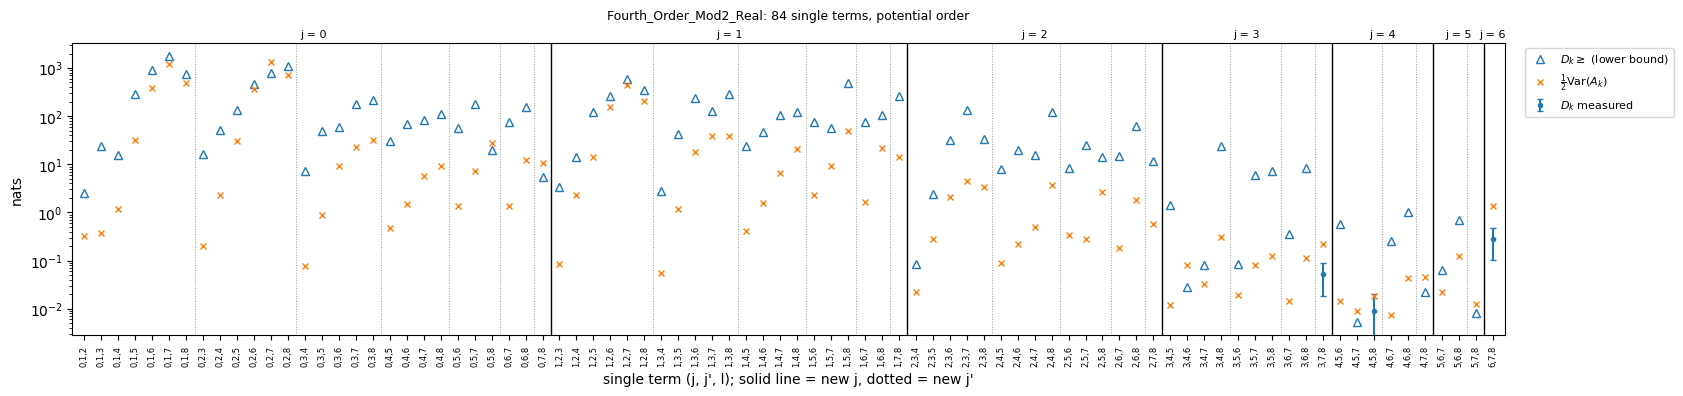

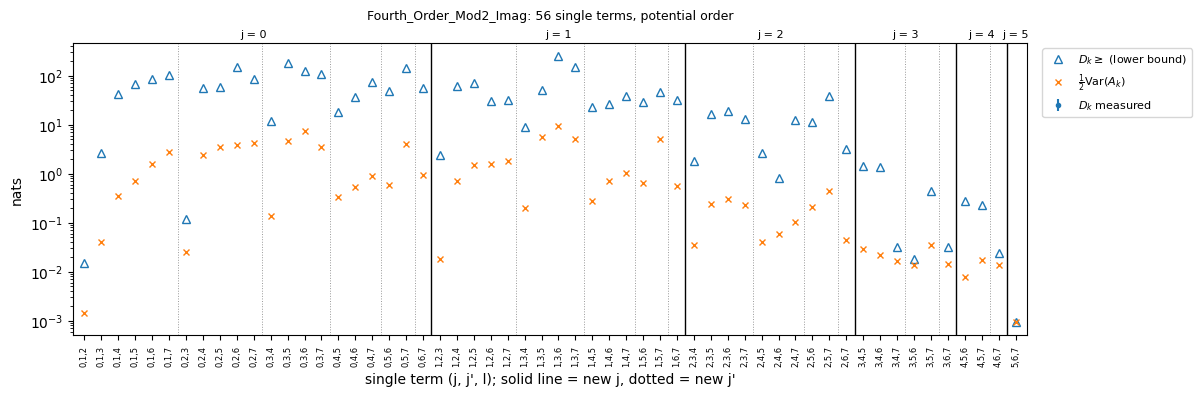

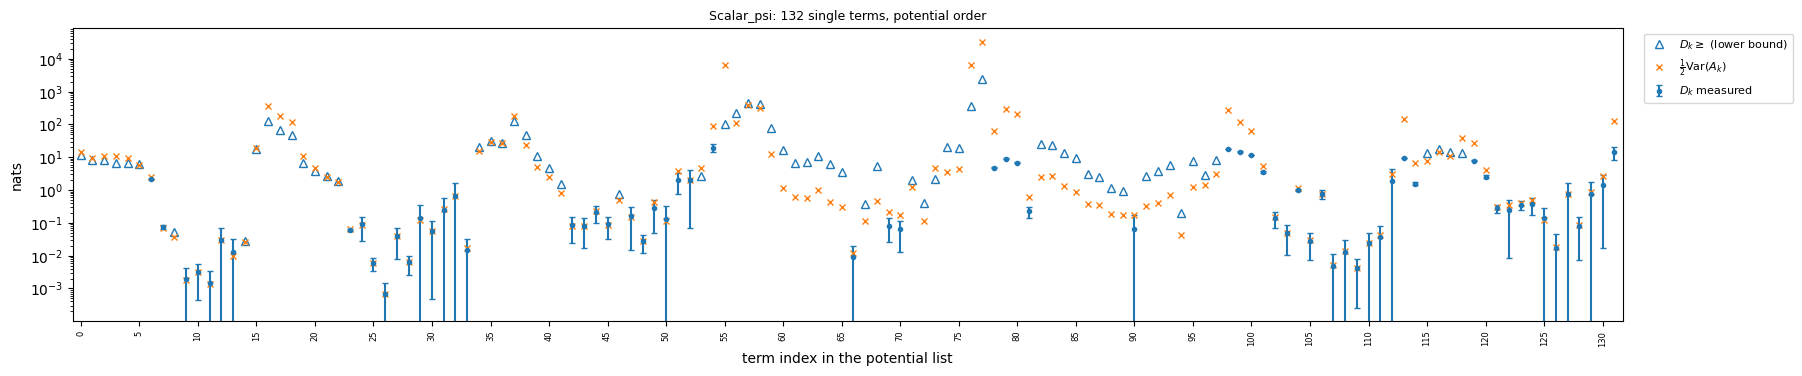

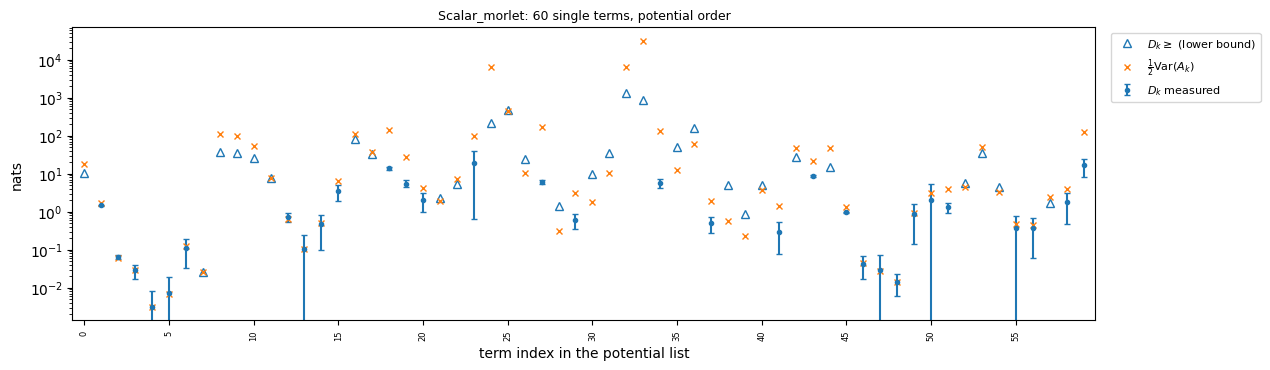

In [4]:
for fam in ('Fourth_Order_Mod2_Real', 'Fourth_Order_Mod2_Imag', 'Scalar_psi', 'Scalar_morlet'):
    if agg.family.str.contains(fam).any():
        P.singles(agg, fam, title=fam); plt.show()

## Diagnostics: ESS of the weights $e^{A_k}$, $\hat D_k$ vs N for the top contributors

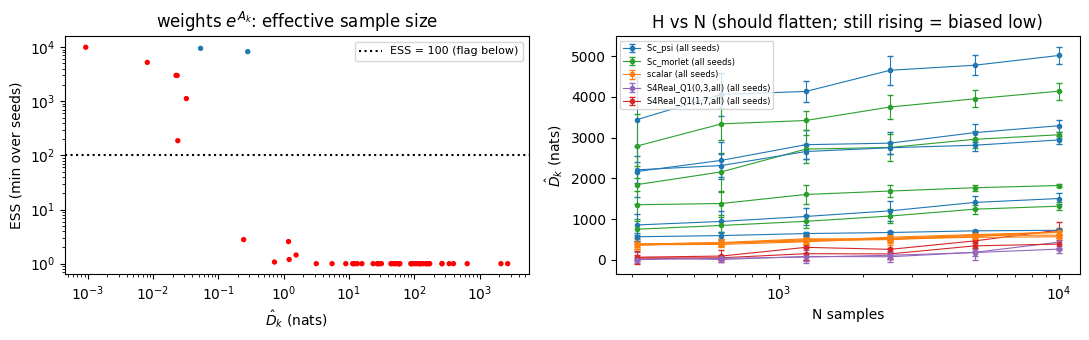

In [5]:
P.diagnostics(agg, DS, Path(os.environ['KL_RESULTS'])); plt.show()

## Summary table (ratio = $D_k / \frac12$Var)

In [6]:
P.summary(agg, kinds=('category', 'family')).drop(columns=['D_lb95_min', 'D_lb_seeds'], errors='ignore').round(4)

,name,n_terms,D_k,regime,khat_max,H_seed_std,H_min,H_max,boot,var2,var2_seed_std,ratio,log10_N_needed,ESS_min,ess,wmax,drift,n_seeds
4,fam:Sc_psi,132,>= 2.7e+03,lower bound,77.2208,1664.7093,728.8557,5016.6506,123.7526,45511.0087,28297.3646,0.0593,19765.1799,1.0,0.0001,1.0,166.8798,5
3,fam:Sc_morlet,60,>= 2.13e+03,lower bound,13.3456,1505.6917,288.6437,4140.5501,85.5312,43308.8166,28153.0674,0.0492,18808.7801,1.0,0.0001,1.0,105.9774,5
0,cat:scalar,192,>= 647,lower bound,45.5466,55.0817,570.9408,699.7898,59.2553,5233.6105,42.4413,0.1237,2272.9282,1.0,0.0001,1.0,72.3967,5
5,fam:S4Imag_Q1,56,>= 59.9,lower bound,2.5354,52.3669,6.0788,140.3800,20.9483,2.3228,1.4119,25.7902,1.0088,1.0,0.0001,1.0,21.9055,5
1,cat:scat4_imag,56,>= 59.9,lower bound,2.5354,52.3669,6.0788,140.3800,20.9483,2.3228,1.4119,25.7902,1.0088,1.0,0.0001,1.0,21.9055,5
2,cat:scat4_real,84,>= 50.3,lower bound,4.3289,49.3634,18.2732,133.6267,15.4702,11.4907,7.8371,4.3817,4.9904,1.0,0.0001,1.0,17.7537,5
6,fam:S4Real_Q1,84,>= 50.3,lower bound,4.3289,49.3634,18.2732,133.6267,15.4702,11.4907,7.8371,4.3817,4.9904,1.0,0.0001,1.0,17.7537,5
